# SUS Analysis

### Imports, paths, and analysis settings

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# PATHS
# --------------------------------------------------
DATA_PATH = Path("datasets/sus_responses.csv")
OUTPUT_DIR = Path("outputs")
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# SUS ITEM DEFINITIONS
# These prefixes match the standard SUS questions.
# The original Google Forms headers can remain intact.
# --------------------------------------------------
ITEM_PREFIXES = [
    "I think that I would like to use this system frequently.",
    "I found the system unnecessarily complex.",
    "I thought the system was easy to use.",
    "I think that I would need the support of a technical person",
    "I found the various functions in this system were well integrated.",
    "I thought there was too much inconsistency in this system.",
    "I would imagine that most people would learn to use the system",
    "I found the system very cumbersome to use.",
    "I felt very confident using the system.",
    "I needed to learn a lot of things before I could get going",
]

print("Input file:", DATA_PATH.resolve())
print("Output directory:", OUTPUT_DIR.resolve())

Input file: /Users/arnel/CODES/MMDC/CAPSTONE1/testbed-requirement-analysis/datasets/sus_responses.csv
Output directory: /Users/arnel/CODES/MMDC/CAPSTONE1/testbed-requirement-analysis/outputs


### Load and validate the data

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_PATH}. "
        "Place sus_responses.csv in the working directory or update DATA_PATH."
    )

raw = pd.read_csv(DATA_PATH)

# Normalize header whitespace only; retain original responses.
raw.columns = [str(c).strip() for c in raw.columns]

print("Raw dataset shape:", raw.shape)
print("\nColumn names detected:")
for col in raw.columns:
    print("-", col)

# Identify the role column dynamically by checking for keywords like 'role'
role_matches = [c for c in raw.columns if "role" in c.strip().lower()]
if len(role_matches) != 1:
    raise ValueError(f"Expected exactly one role column, found: {role_matches}")

role_col = role_matches[0]

# Standard SUS item prefixes to match against columns
ITEM_PREFIXES = [
    "I think that I would like to use this system frequently",
    "I found the system unnecessarily complex",
    "I thought the system was easy to use",
    "I think that I would need the support of a technical person",
    "I found the various functions in this system were well integrated",
    "I thought there was too much inconsistency in this system",
    "I would imagine that most people would learn to use this system",
    "I found the system very cumbersome to use",
    "I felt very confident using the system",
    "I needed to learn a lot of things before I could get going"
]

item_columns = []
for prefix in ITEM_PREFIXES:
    matches = [c for c in raw.columns if c.startswith(prefix)]
    if len(matches) != 1:
        raise ValueError(
            f"Expected one matching column for SUS item starting with:\n'{prefix}'\n"
            f"Found matches: {matches}"
        )
    item_columns.append(matches[0])

# Identify the comment column (any remaining column that isn't timestamp, role, or an SUS item)
excluded = set(item_columns + [role_col])
other_columns = [c for c in raw.columns if c not in excluded]

timestamp_columns = [
    c for c in other_columns
    if c.strip().lower() in {"timestamp", "date", "submitted at"}
]

comment_columns = [
    c for c in other_columns
    if c not in timestamp_columns
]

comment_col = comment_columns[0] if comment_columns else None

# Build clean analysis dataset
analysis = pd.DataFrame()
analysis["Role"] = raw[role_col].astype("string").str.strip()

for i, col in enumerate(item_columns, start=1):
    analysis[f"Q{i}"] = pd.to_numeric(raw[col], errors="coerce")

if comment_col:
    analysis["Comment"] = raw[comment_col].fillna("").astype(str).str.strip()
else:
    analysis["Comment"] = ""

# Validation checks
sus_cols = [f"Q{i}" for i in range(1, 11)]

invalid_values = {}
for col in sus_cols:
    values = analysis[col].dropna()
    invalid = values[~values.isin([1, 2, 3, 4, 5])]
    if not invalid.empty:
        invalid_values[col] = invalid.tolist()

missing_items = analysis[sus_cols].isna().sum()
incomplete_rows = analysis[sus_cols].isna().any(axis=1)

print("\n--- Validation Summary ---")
print("Respondent count:", len(analysis))
print("Incomplete SUS responses:", int(incomplete_rows.sum()))
print("\nMissing values by item:")
print(missing_items.to_frame("Missing responses"))

if invalid_values:
    print("\nInvalid response values detected:", invalid_values)
else:
    print("\nAll observed SUS responses are within the 1–5 range.")

if incomplete_rows.any() or invalid_values:
    raise ValueError(
        "Resolve missing or invalid SUS item responses before scoring. "
        "Do not silently impute missing values."
    )

if analysis["Role"].isna().any() or (analysis["Role"] == "").any():
    warnings.warn("Some respondents have missing role labels.")

print("\nCleaned dataset preview:")
print(analysis.head())

Raw dataset shape: (15, 13)

Column names detected:
- Timestamp
- What is your current or previous role in the internship process?
- I think that I would like to use this system frequently.
- I found the system unnecessarily complex.
- I thought the system was easy to use.
- I think that I would need the support of a technical person to be able to use this system.
- I found the various functions in this system were well integrated.
- I thought there was too much inconsistency in this system.
- I would imagine that most people would learn to use this system very quickly.
- I found the system very cumbersome to use.
- I felt very confident using the system.
- I needed to learn a lot of things before I could get going with this system.
- Any comments, observation or suggestions about your experience using the app.

--- Validation Summary ---
Respondent count: 15
Incomplete SUS responses: 0

Missing values by item:
     Missing responses
Q1                   0
Q2                   0
Q3    

### Calculate standard SUS scores

In [3]:
# Adjust each item according to standard SUS scoring.
adjusted = pd.DataFrame(index=analysis.index)

for i in range(1, 11):
    col = f"Q{i}"

    if i % 2 == 1:
        # Positive-worded item
        adjusted[col] = analysis[col] - 1
    else:
        # Negative-worded item
        adjusted[col] = 5 - analysis[col]

# Calculate each respondent's total SUS score.
analysis["SUS_Score"] = adjusted[sus_cols].sum(axis=1) * 2.5

# Save a scoring audit table.
audit = analysis[["Role"] + sus_cols + ["SUS_Score"]].copy()
audit.insert(0, "Respondent_ID", [f"R{i:02d}" for i in range(1, len(audit) + 1)])

audit.to_csv(TABLE_DIR / "sus_scoring_audit.csv", index=False)

display(audit)

print("SUS scoring audit saved.")

,Respondent_ID,Role,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,SUS_Score
0,R01,Student,3,3,5,4,3,2,4,3,4,4,57.5
1,R02,Student,5,1,4,1,5,1,4,1,4,1,92.5
2,R03,OJT/Internship Coordinator,4,5,5,2,4,1,4,2,4,3,70.0
3,R04,Student,5,1,5,1,5,1,5,1,5,1,100.0
4,R05,Student,1,1,1,5,1,5,1,5,1,5,10.0
5,R06,Faculty Adviser,4,1,5,2,4,1,4,2,4,2,82.5
6,R07,Student,5,1,5,1,5,1,5,1,5,1,100.0
7,R08,Student,5,5,5,1,5,1,5,1,5,1,90.0
8,R09,HTE Supervisor/Personnel,5,2,3,1,4,2,4,2,4,1,80.0
9,R10,Faculty Adviser,4,2,3,2,3,3,3,3,4,3,60.0


SUS scoring audit saved.


### Overall descriptive statistics

In [4]:
scores = analysis["SUS_Score"]

summary = pd.DataFrame({
    "Statistic": [
        "Number of respondents",
        "Mean SUS score",
        "Median SUS score",
        "Standard deviation",
        "Minimum score",
        "Maximum score",
        "First quartile (Q1)",
        "Third quartile (Q3)",
        "Interquartile range",
    ],
    "Value": [
        scores.count(),
        scores.mean(),
        scores.median(),
        scores.std(ddof=1),
        scores.min(),
        scores.max(),
        scores.quantile(0.25),
        scores.quantile(0.75),
        scores.quantile(0.75) - scores.quantile(0.25),
    ]
})

summary["Value"] = summary["Value"].round(2)

summary.to_csv(TABLE_DIR / "sus_overall_summary.csv", index=False)
display(summary)

# Role profile
role_summary = (
    analysis["Role"]
    .value_counts(dropna=False)
    .rename_axis("Role")
    .reset_index(name="Respondents")
)

role_summary["Percentage"] = (
    role_summary["Respondents"] / len(analysis) * 100
).round(1)

role_summary.to_csv(TABLE_DIR / "sus_respondent_profile.csv", index=False)
display(role_summary)

,Statistic,Value
0,Number of respondents,15.00
1,Mean SUS score,78.17
2,Median SUS score,82.50
3,Standard deviation,23.95
4,Minimum score,10.00
5,Maximum score,100.00
6,First quartile (Q1),67.50
7,Third quartile (Q3),95.00
8,Interquartile range,27.50


,Role,Respondents,Percentage
0,Student,8,53.3
1,Faculty Adviser,3,20.0
2,OJT/Internship Coordinator,2,13.3
3,HTE Supervisor/Personnel,1,6.7
4,IMS Administrator,1,6.7


### Figure for Distribution of SUS scores

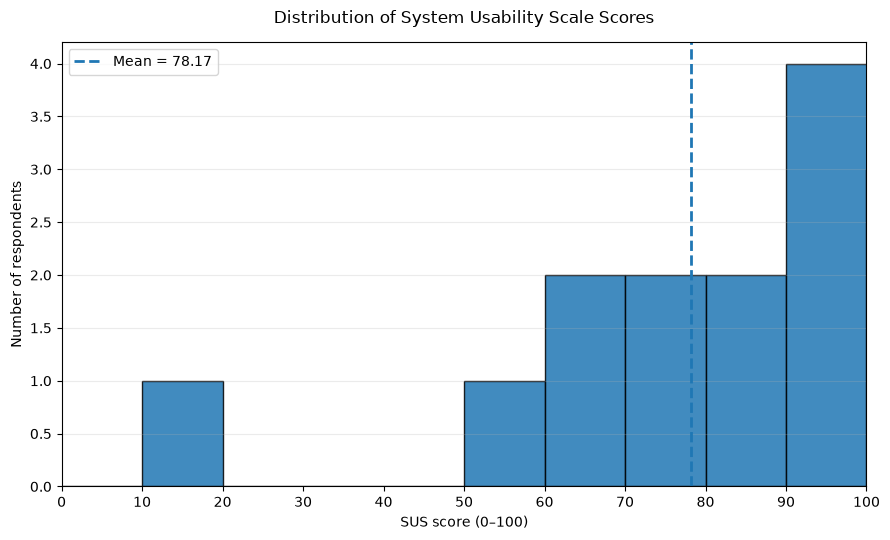

In [5]:
fig, ax = plt.subplots(figsize=(9, 5.5))

ax.hist(
    scores,
    bins=np.arange(0, 111, 10),
    edgecolor="black",
    alpha=0.85
)

ax.axvline(
    scores.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Mean = {scores.mean():.2f}"
)

ax.set_title("Distribution of System Usability Scale Scores", pad=14)
ax.set_xlabel("SUS score (0–100)")
ax.set_ylabel("Number of respondents")
ax.set_xlim(0, 100)
ax.set_xticks(np.arange(0, 101, 10))
ax.legend()
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "figure_4_7_1_sus_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Figure for Individual respondent scores

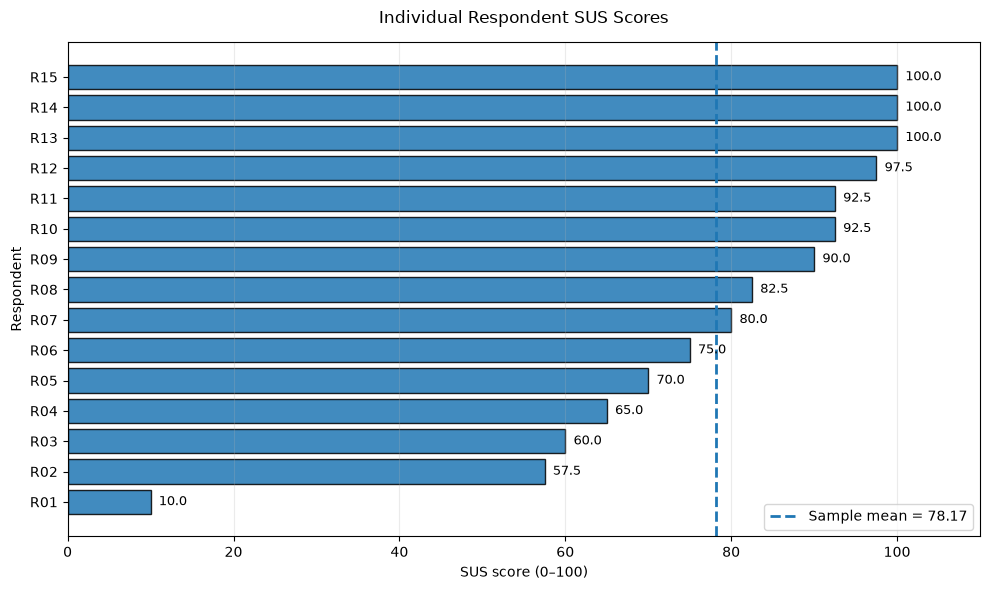

In [6]:
plot_data = audit.sort_values("SUS_Score").reset_index(drop=True)
plot_data["Display_ID"] = [
    f"R{i:02d}" for i in range(1, len(plot_data) + 1)
]

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    plot_data["Display_ID"],
    plot_data["SUS_Score"],
    edgecolor="black",
    alpha=0.85
)

ax.axvline(
    scores.mean(),
    linestyle="--",
    linewidth=2,
    label=f"Sample mean = {scores.mean():.2f}"
)

for bar, value in zip(bars, plot_data["SUS_Score"]):
    ax.text(
        value + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.1f}",
        va="center",
        fontsize=9
    )

ax.set_title("Individual Respondent SUS Scores", pad=14)
ax.set_xlabel("SUS score (0–100)")
ax.set_ylabel("Respondent")
ax.set_xlim(0, 110)
ax.legend()
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "figure_4_7_2_individual_sus_scores.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Figure for Item-level usability results

,Item,Statement,Favorable_Direction_Mean,Favorable_Responses_4_or_5_Pct
0,Q1,Q1: Frequent use,4.20,80.0
1,Q2,Q2: Not unnecessarily complex,4.07,80.0
2,Q3,Q3: Easy to use,4.07,66.7
3,Q4,Q4: Little technical support needed,4.33,86.7
4,Q5,Q5: Functions well integrated,3.93,73.3
5,Q6,Q6: Consistent system,4.20,80.0
6,Q7,Q7: Quick to learn,4.13,86.7
7,Q8,Q8: Not cumbersome,4.13,80.0
8,Q9,Q9: User confidence,4.20,93.3
9,Q10,Q10: Easy to get started,4.00,66.7


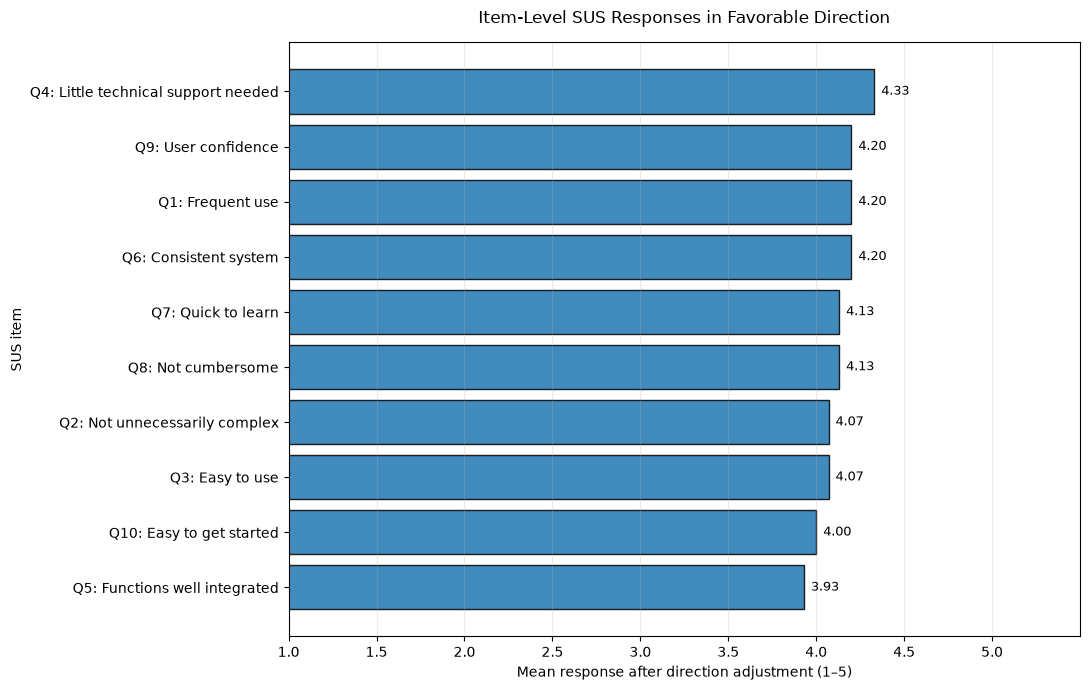

In [7]:
# Convert responses to a consistent favorable direction.
favorable = pd.DataFrame(index=analysis.index)

for i in range(1, 11):
    col = f"Q{i}"

    if i % 2 == 1:
        favorable[col] = analysis[col]
    else:
        favorable[col] = 6 - analysis[col]

item_labels = [
    "Q1: Frequent use",
    "Q2: Not unnecessarily complex",
    "Q3: Easy to use",
    "Q4: Little technical support needed",
    "Q5: Functions well integrated",
    "Q6: Consistent system",
    "Q7: Quick to learn",
    "Q8: Not cumbersome",
    "Q9: User confidence",
    "Q10: Easy to get started",
]

item_summary = pd.DataFrame({
    "Item": [f"Q{i}" for i in range(1, 11)],
    "Statement": item_labels,
    "Favorable_Direction_Mean": [
        favorable[f"Q{i}"].mean() for i in range(1, 11)
    ],
    "Favorable_Responses_4_or_5_Pct": [
        (favorable[f"Q{i}"] >= 4).mean() * 100
        for i in range(1, 11)
    ],
})

item_summary["Favorable_Direction_Mean"] = (
    item_summary["Favorable_Direction_Mean"].round(2)
)
item_summary["Favorable_Responses_4_or_5_Pct"] = (
    item_summary["Favorable_Responses_4_or_5_Pct"].round(1)
)

item_summary.to_csv(TABLE_DIR / "sus_item_level_summary.csv", index=False)
display(item_summary)

# Chart of mean responses in favorable direction.
fig, ax = plt.subplots(figsize=(11, 7))

ordered = item_summary.sort_values("Favorable_Direction_Mean")

bars = ax.barh(
    ordered["Statement"],
    ordered["Favorable_Direction_Mean"],
    edgecolor="black",
    alpha=0.85
)

for bar, value in zip(bars, ordered["Favorable_Direction_Mean"]):
    ax.text(
        value + 0.04,
        bar.get_y() + bar.get_height() / 2,
        f"{value:.2f}",
        va="center",
        fontsize=9
    )

ax.set_title("Item-Level SUS Responses in Favorable Direction", pad=14)
ax.set_xlabel("Mean response after direction adjustment (1–5)")
ax.set_ylabel("SUS item")
ax.set_xlim(1, 5.5)
ax.set_xticks(np.arange(1, 5.1, 0.5))
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "figure_4_7_3_sus_item_means.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### SUS scores by respondent role

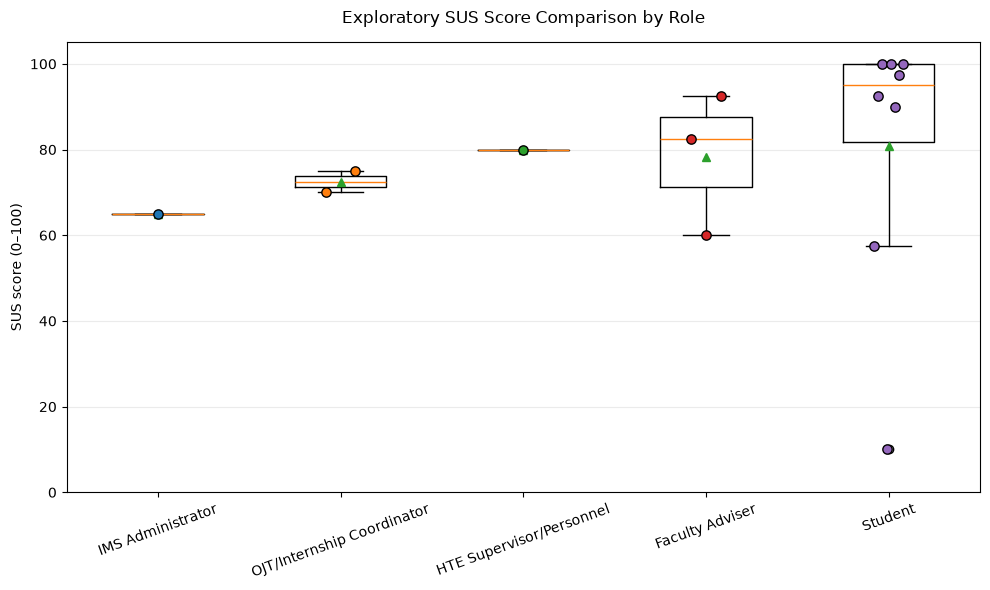

In [8]:
# Individual observations are shown so small groups remain visible.
role_order = (
    analysis.groupby("Role")["SUS_Score"]
    .median()
    .sort_values()
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(10, 6))

role_values = [
    analysis.loc[analysis["Role"] == role, "SUS_Score"].to_numpy()
    for role in role_order
]

# Fixed boxplot call
bp = ax.boxplot(
    role_values,
    showmeans=True
)

ax.set_xticks(range(1, len(role_order) + 1))
ax.set_xticklabels(role_order)

# Overlay the individual scores.
for x, role in enumerate(role_order, start=1):
    values = analysis.loc[
        analysis["Role"] == role, "SUS_Score"
    ].to_numpy()

    # Deterministic offsets keep points separated without randomness.
    offsets = np.linspace(-0.08, 0.08, len(values)) if len(values) > 1 else [0]

    ax.scatter(
        np.full(len(values), x) + offsets,
        values,
        s=45,
        edgecolors="black",
        zorder=3
    )

ax.set_title("Exploratory SUS Score Comparison by Role", pad=14)
ax.set_ylabel("SUS score (0–100)")
ax.set_ylim(0, 105)
ax.tick_params(axis="x", labelrotation=20)
ax.grid(axis="y", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "figure_4_7_4_sus_by_role.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Analyze the open-ended comments
> The following is a transparent keyword-assisted screening step that can flag comments for review and produces an initial theme count

In [9]:
comments = analysis[["Role", "Comment"]].copy()
comments.insert(
    0,
    "Respondent_ID",
    [f"R{i:02d}" for i in range(1, len(comments) + 1)]
)

# Exploratory keyword rules. One comment may match multiple themes.
theme_rules = {
    "Navigation and ease of use": [
        r"\bnavigat", r"\beasy to use\b", r"\bstraightforward\b",
        r"\borganized\b", r"\bsimple\b", r"\bmenu\b"
    ],
    "Error messages and validation": [
        r"\berror message", r"\brequest failed\b", r"\bvalidation\b",
        r"\btime out\b", r"\btime-in\b", r"\btime in\b",
        r"\bdata accuracy\b"
    ],
    "Dashboard and progress visibility": [
        r"\bdashboard\b", r"\bprogress\b", r"\bremaining hours\b",
        r"\bpending logs\b", r"\bshortcut\b", r"\bcounts\b"
    ],
    "Workflow and evaluation management": [
        r"\bevaluation\b", r"\bstudent selection\b", r"\bdraft\b",
        r"\bsave confirmation\b", r"\bunsaved changes\b",
        r"\beligibility\b", r"\bevaluate\b"
    ],
    "Performance and responsiveness": [
        r"\bslow\b", r"\bperformance\b", r"\bresponsiveness\b",
        r"\bseveral times\b", r"\blatency\b"
    ],
    "Data entry and dropdowns": [
        r"\bdropdown\b", r"\bautocomplete\b", r"\bauto-complete\b",
        r"\bsample data\b", r"\bdummy data\b"
    ],
    "Attendance controls": [
        r"\bfuture attendance\b", r"\bfuture dates\b",
        r"\battendance\b"
    ],
    "Visual design and accessibility": [
        r"\bcontrast\b", r"\bcolor\b", r"\bbranding\b",
        r"\bprofile picture\b", r"\bicon\b", r"\btooltip\b",
        r"\bkeyboard\b", r"\baria\b", r"\breadability\b"
    ],
    "Terminology and instructions": [
        r"\binstructions\b", r"\bterminology\b", r"\brename\b",
        r"\bmy profile\b", r"\babout us\b", r"\binconsisten"
    ],
    "Document handling": [
        r"\bdocument", r"\bdownload\b", r"\bupload\b"
    ],
}

def find_themes(comment):
    text = str(comment).lower()
    matched = []

    for theme, patterns in theme_rules.items():
        if any(re.search(pattern, text) for pattern in patterns):
            matched.append(theme)

    return matched

comments["Flagged_Themes"] = comments["Comment"].apply(find_themes)

# Export the comment-level screening results for manual review.
comments.to_csv(
    TABLE_DIR / "sus_comment_theme_screening.csv",
    index=False
)

display(comments[["Respondent_ID", "Role", "Comment", "Flagged_Themes"]])

,Respondent_ID,Role,Comment,Flagged_Themes
0,R01,Student,,[]
1,R02,Student,"Overall, the app was easy to navigate and the ...","[Navigation and ease of use, Error messages an..."
2,R03,OJT/Internship Coordinator,Im not sure if it is part of the functional pr...,[]
3,R04,Student,I'd gladly use this website because during my ...,"[Dashboard and progress visibility, Attendance..."
4,R05,Student,none,[]
5,R06,Faculty Adviser,The prototype is easy to navigate from my assi...,"[Navigation and ease of use, Terminology and i..."
6,R07,Student,The system was so easy to navigate and use,[Navigation and ease of use]
7,R08,Student,,[]
8,R09,HTE Supervisor/Personnel,,[]
9,R10,Faculty Adviser,Overall Impression\n\nThe task flow was clear ...,"[Navigation and ease of use, Dashboard and pro..."


### Create the theme frequency table and chart

,Theme,Respondents_Mentioning_Theme,Percentage_of_All_Respondents
3,Workflow and evaluation management,1,6.7
1,Error messages and validation,2,13.3
6,Attendance controls,2,13.3
4,Performance and responsiveness,2,13.3
5,Data entry and dropdowns,3,20.0
7,Visual design and accessibility,3,20.0
2,Dashboard and progress visibility,4,26.7
9,Document handling,4,26.7
8,Terminology and instructions,5,33.3
0,Navigation and ease of use,8,53.3


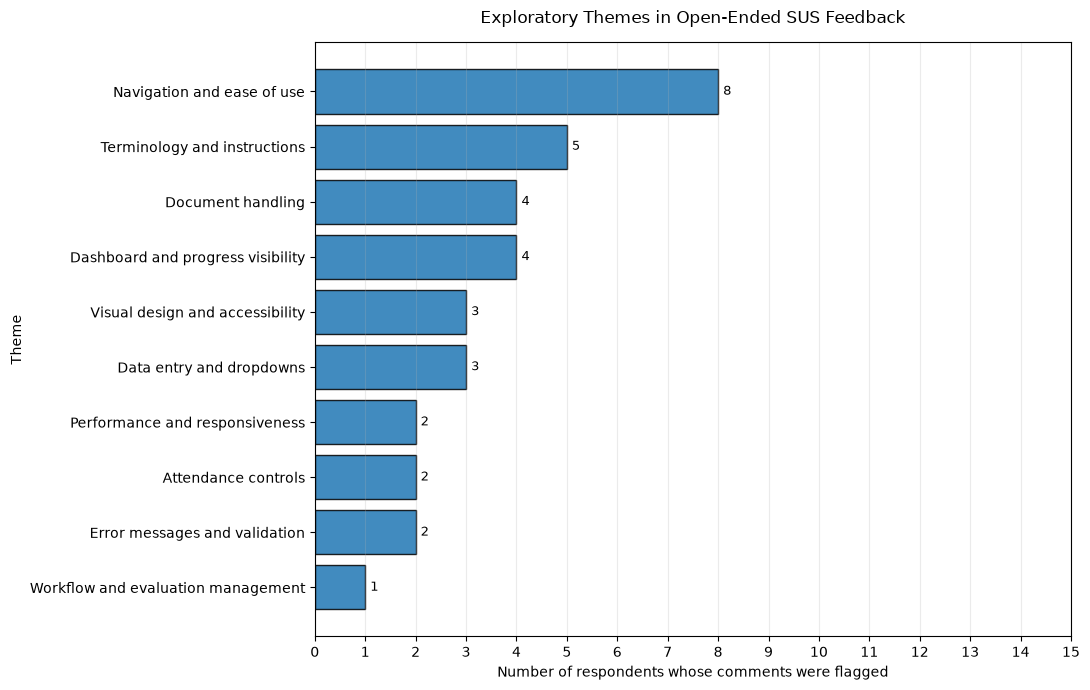

In [10]:
theme_counts = {}

for theme in theme_rules:
    theme_counts[theme] = sum(
        theme in themes for themes in comments["Flagged_Themes"]
    )

theme_summary = pd.DataFrame({
    "Theme": list(theme_counts.keys()),
    "Respondents_Mentioning_Theme": list(theme_counts.values())
})

theme_summary["Percentage_of_All_Respondents"] = (
    theme_summary["Respondents_Mentioning_Theme"]
    / len(analysis) * 100
).round(1)

theme_summary = theme_summary.sort_values(
    "Respondents_Mentioning_Theme",
    ascending=True
)

theme_summary.to_csv(
    TABLE_DIR / "sus_qualitative_theme_screening.csv",
    index=False
)

display(theme_summary)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    theme_summary["Theme"],
    theme_summary["Respondents_Mentioning_Theme"],
    edgecolor="black",
    alpha=0.85
)

for bar, count in zip(
    bars,
    theme_summary["Respondents_Mentioning_Theme"]
):
    ax.text(
        count + 0.1,
        bar.get_y() + bar.get_height() / 2,
        str(count),
        va="center",
        fontsize=9
    )

ax.set_title("Exploratory Themes in Open-Ended SUS Feedback", pad=14)
ax.set_xlabel("Number of respondents whose comments were flagged")
ax.set_ylabel("Theme")
ax.set_xlim(0, max(2, theme_summary["Respondents_Mentioning_Theme"].max() + 2))
ax.set_xticks(range(0, len(analysis) + 1, 1))
ax.grid(axis="x", alpha=0.25)

fig.tight_layout()
fig.savefig(
    FIGURE_DIR / "figure_4_7_5_sus_feedback_themes.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()